# Course 2: Ten Years of Deep Learning Ideas
## Session 1: Making depth work: residuals, normalization and µP

**Goal:** measure how signals vanish or explode in deep networks, fix them with residual connections and normalization, and run a µP coordinate check and a learning-rate sweep across widths.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Setup and data
We use scikit-learn's 8x8 digits (1,797 images, 64 pixels, 10 classes), standardized with the training-set mean and standard deviation. All networks here are small multilayer perceptrons (MLPs), so everything runs on a CPU. The ideas in this session were developed on ImageNet ResNets and large transformers; the toy versions show the same mechanisms, not the same numbers.

In [1]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

torch.set_num_threads(2)          # tiny models run as fast on 2 threads, and shared machines stay responsive
torch.set_flush_denormal(True)    # treat extremely small numbers as 0 (avoids very slow arithmetic in exploding nets)
torch.manual_seed(0); np.random.seed(0)

digits = load_digits()
X_all = torch.tensor(digits.data, dtype=torch.float32)
y_all = torch.tensor(digits.target)
Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=0.25, random_state=0, stratify=y_all)
mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-3
Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd          # standardize with training statistics only
print(f"training set {tuple(Xtr.shape)}, test set {tuple(Xte.shape)}")

training set (1347, 64), test set (450, 64)


### 2. Signals at initialization: plain versus residual networks
We build 50-layer MLPs of width 128 in four versions and look at them **before any training**:

1. **plain, default init**: `h = W relu(h)` with PyTorch's default `nn.Linear` initialization, whose weight variance is 1/(3 fan_in). For ReLU this is too small: He et al. (2015) showed you need 2/fan_in to keep the variance constant.
2. **plain, He init**: the same network with weight variance 2/fan_in.
3. **residual, no norm**: `h = h + W relu(h)`, He init in the branch.
4. **residual + LayerNorm**: `h = h + W relu(LN(h))`, the pre-normalization form used in modern transformers.

For each layer we measure two things: how much the activations differ between examples (the forward signal; if it goes to zero, the network has forgotten its input), and the root mean square (RMS) of the loss gradient with respect to the activations (the backward signal). A healthy network keeps both roughly constant across layers.

plain, default init    forward spread: layer 1 1.9e-01, layer 50 2.3e-09 | gradient RMS: layer 1 1.4e-23, layer 50 1.4e-04
plain, He init         forward spread: layer 1 4.6e-01, layer 50 6.7e-02 | gradient RMS: layer 1 8.6e-05, layer 50 1.4e-04
residual, no norm      forward spread: layer 1 7.2e-01, layer 50 4.1e+06 | gradient RMS: layer 1 3.8e+03, layer 50 1.9e-04
residual + LayerNorm   forward spread: layer 1 9.8e-01, layer 50 3.9e+00 | gradient RMS: layer 1 1.0e-03, layer 50 1.7e-04


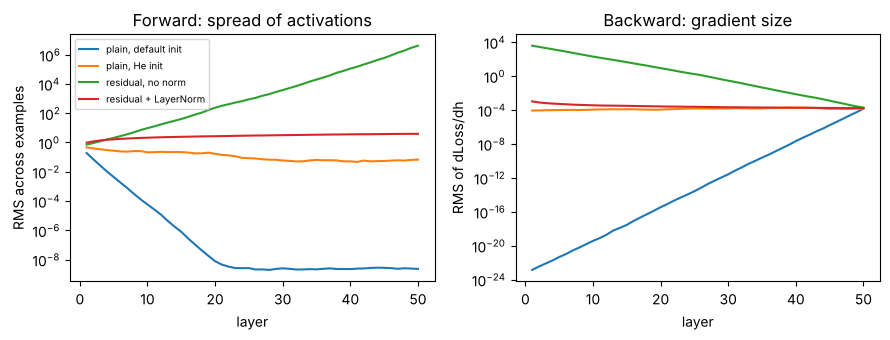

In [2]:
class RMSNorm(nn.Module):
    """y = g * x / sqrt(mean(x^2) + eps): LayerNorm without the mean subtraction and the bias (Zhang & Sennrich 2019)."""
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.g, self.eps = nn.Parameter(torch.ones(d)), eps

    def forward(self, x):
        return self.g * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)


class DeepMLP(nn.Module):
    def __init__(self, depth, width=128, residual=False, norm=None, init="he", rezero=False):
        super().__init__()
        self.inp, self.out = nn.Linear(64, width), nn.Linear(width, 10)
        self.layers = nn.ModuleList([nn.Linear(width, width) for _ in range(depth)])
        make_norm = {"layernorm": lambda: nn.LayerNorm(width), "rmsnorm": lambda: RMSNorm(width), None: nn.Identity}[norm]
        self.norms = nn.ModuleList([make_norm() for _ in range(depth)])
        self.residual = residual
        self.alpha = nn.Parameter(torch.zeros(depth)) if rezero else None   # ReZero: one scalar per branch, starting at 0
        if init == "he":
            for lin in self.layers:
                nn.init.kaiming_normal_(lin.weight, nonlinearity="relu")
                nn.init.zeros_(lin.bias)
        # init == "default" keeps PyTorch's nn.Linear default (weight variance 1/(3 fan_in), small random biases)

    def forward(self, x, record=None):
        h = self.inp(x)
        for i, (lin, norm) in enumerate(zip(self.layers, self.norms)):
            if self.residual:
                branch = lin(F.relu(norm(h)))
                h = h + (self.alpha[i] * branch if self.alpha is not None else branch)
            else:
                h = lin(F.relu(h))
            if record is not None:
                h.retain_grad()
                record.append(h)
        return self.out(F.relu(h))


def signal_profile(model, n=256):
    acts = []
    loss = F.cross_entropy(model(Xtr[:n], record=acts), ytr[:n])
    loss.backward()
    to64 = lambda t: t.detach().double()        # float64, because squares of tiny gradients underflow in float32
    spread = [(to64(a) - to64(a).mean(0)).pow(2).mean().sqrt().item() for a in acts]   # differences between examples
    grad_rms = [to64(a.grad).pow(2).mean().sqrt().item() for a in acts]
    return np.array(spread), np.array(grad_rms)


INIT_CONFIGS = {
    "plain, default init": dict(init="default"),
    "plain, He init": dict(init="he"),
    "residual, no norm": dict(residual=True),
    "residual + LayerNorm": dict(residual=True, norm="layernorm"),
}
profiles = {}
for name, cfg in INIT_CONFIGS.items():
    torch.manual_seed(0)
    profiles[name] = signal_profile(DeepMLP(depth=50, **cfg))
    s, g = profiles[name]
    print(f"{name:22s} forward spread: layer 1 {s[0]:.1e}, layer 50 {s[-1]:.1e} | "
          f"gradient RMS: layer 1 {g[0]:.1e}, layer 50 {g[-1]:.1e}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
for name, (s, g) in profiles.items():
    ax[0].semilogy(range(1, 51), s, label=name)
    ax[1].semilogy(range(1, 51), g, label=name)
ax[0].set(title="Forward: spread of activations", xlabel="layer", ylabel="RMS across examples")
ax[1].set(title="Backward: gradient size", xlabel="layer", ylabel="RMS of dLoss/dh")
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

Read the gradient curves from right to left: the gradient starts at the output (layer 50) and travels back to layer 1. With the default initialization, each layer multiplies the gradient by about 0.4 (the variance factor is fan_in x 1/(3 fan_in) x 1/2 = 1/6, and the square root of 1/6 is 0.41), so after 49 layers it is about 10^-19 times smaller. The differences between examples fade on the forward pass too, until they are below float32 rounding. He initialization keeps both signals roughly level. The unnormalized residual network has the opposite problem: every block adds a branch about as large as its input, so the variance roughly doubles per block. With pre-LayerNorm the residual stream still grows, but only slowly, because each branch sees a normalized input.

### 3. Train briefly: which deep networks learn?
Now we train 32-layer versions (width 64) for 300 steps of SGD with momentum 0.9 and batch 128, at two learning rates, 0.003 and 0.03. A single learning rate would be unfair: some networks only train when the step is small. Two more variants join: residual + RMSNorm, and ReZero (Bachlechner et al. 2020), which has no normalization but multiplies each branch by a learned scalar that starts at 0, so the network starts as the identity map. We use SGD because it shows the effect of gradient size directly; Adam rescales each parameter's step, which hides part of the problem (see the TODO).

test accuracy after 300 steps (training loss in brackets)
network                  lr 0.003            lr 0.03          


plain, default init      0.102 (2.303)       0.100 (2.302)    


plain, He init           0.771 (0.708)       0.096 (2.302)    


residual, no norm        diverged (NaN)        diverged (NaN)     


residual + LayerNorm     0.927 (0.007)       0.962 (0.000)    


residual + RMSNorm       0.947 (0.007)       0.969 (0.001)    


residual, ReZero         0.931 (0.109)       0.960 (0.000)    
(twelve runs took 41 s)


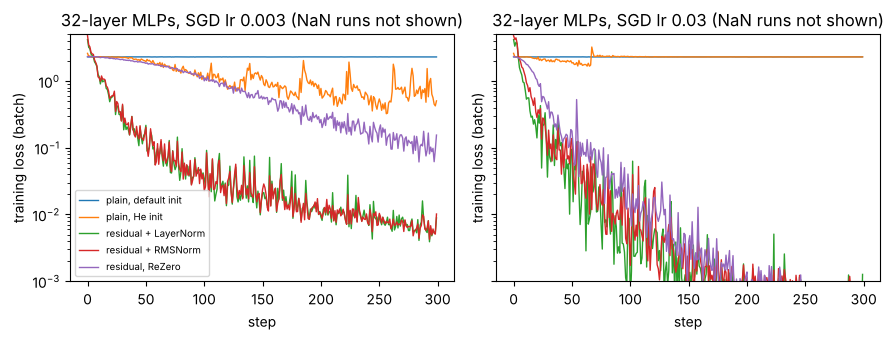

In [3]:
def train(model, steps=300, lr=0.02, bs=128, seed=0):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    losses = []
    for step in range(steps):
        idx = torch.randint(len(Xtr), (bs,), generator=g)
        loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    with torch.no_grad():
        acc = (model(Xte).argmax(1) == yte).float().mean().item()
    return losses, acc


TRAIN_CONFIGS = dict(INIT_CONFIGS)
TRAIN_CONFIGS["residual + RMSNorm"] = dict(residual=True, norm="rmsnorm")
TRAIN_CONFIGS["residual, ReZero"] = dict(residual=True, rezero=True)
LRS = [0.003, 0.03]
curves, results = {}, {}
t0 = time.time()
print("test accuracy after 300 steps (training loss in brackets)")
print(f"{'network':22s}" + "".join(f"   lr {lr:<14g}" for lr in LRS))
for name, cfg in TRAIN_CONFIGS.items():
    row = f"{name:22s}"
    for lr in LRS:
        torch.manual_seed(0)
        c, acc = train(DeepMLP(depth=32, width=64, **cfg), lr=lr)
        last = np.mean(c[-20:])
        curves[(name, lr)], results[(name, lr)] = c, (acc, last)
        row += f"   {'diverged (NaN)':19s}" if not math.isfinite(last) else f"   {acc:.3f} ({last:.3f})    "
    print(row)
print(f"(twelve runs took {time.time() - t0:.0f} s)")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for k, lr in enumerate(LRS):
    for name in TRAIN_CONFIGS:
        c = np.array(curves[(name, lr)])
        if np.isfinite(c).all():
            ax[k].plot(c, label=name, lw=1)
    ax[k].set(yscale="log", ylim=(1e-3, 5), title=f"32-layer MLPs, SGD lr {lr} (NaN runs not shown)",
              xlabel="step", ylabel="training loss (batch)")
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 4. Width: the µP coordinate check
Now fix the depth (three hidden layers) and change the **width** from 32 to 2,048. Under the standard parameterization (SP), every weight starts with variance about 1/fan_in and every layer uses the same Adam learning rate. Adam moves each weight by roughly the learning rate per step, whatever the width, and a hidden unit sums over `width` inputs, so the change in its value grows with width.

The maximal update parameterization (µP; Yang & Hu 2021; Yang et al. 2022) fixes this. For Adam, with a base width of 32 where µP and SP agree:

| | input layer | hidden layers | output layer |
|---|---|---|---|
| initial variance | 2/fan_in (both) | 2/fan_in (both) | SP 1/fan_in; µP 32/fan_in² |
| Adam learning rate | η (both) | SP η; µP η·32/width | SP η; µP η·32/width |

Biases keep learning rate η. A **coordinate check** trains each width for a few steps and measures the typical size of the activations. If it changes with width, the parameterization is wrong; under µP the curves should be flat.

SP: mean |coordinate| after 5 Adam steps (lr 1e-2)
   width   hidden 1  hidden 2  hidden 3    logits
      32     0.539     0.464     0.361     0.620
      64     0.535     0.623     0.739     1.326
     128     0.530     0.566     0.642     1.890
     256     0.501     0.459     0.632     2.423
     512     0.465     0.226     0.376     2.453
    1024     0.441     0.290     0.875    13.124
    2048     0.446     0.176     0.902    24.630


muP: mean |coordinate| after 5 Adam steps (lr 1e-2)
   width   hidden 1  hidden 2  hidden 3    logits
      32     0.539     0.464     0.361     0.620
      64     0.538     0.599     0.632     0.810
     128     0.558     0.577     0.633     0.715
     256     0.546     0.610     0.707     0.635
     512     0.560     0.638     0.754     0.655
    1024     0.555     0.633     0.745     0.658
    2048     0.557     0.653     0.799     0.662


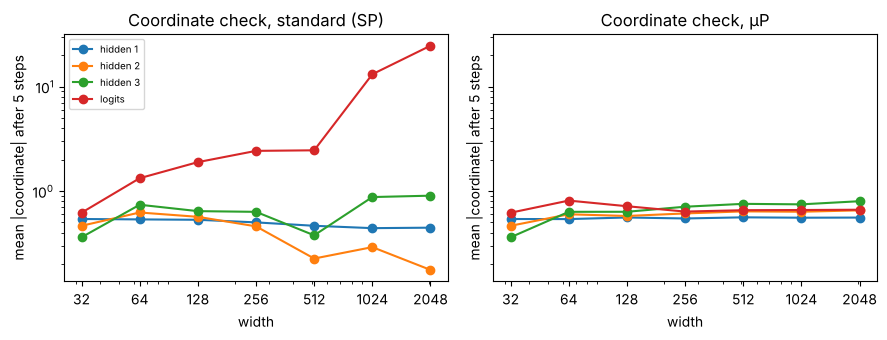

In [4]:
BASE = 32

def make_mlp(width, param, seed=0):
    """Three hidden layers. param is "SP" or "muP". Returns the parameters and one learning-rate multiplier per parameter."""
    torch.manual_seed(seed)
    W = [torch.randn(width, 64) * math.sqrt(2 / 64),              # input layer: fan_in is 64 at every width
         torch.randn(width, width) * math.sqrt(2 / width),        # hidden layers
         torch.randn(width, width) * math.sqrt(2 / width),
         torch.randn(10, width) * (math.sqrt(1 / width) if param == "SP" else math.sqrt(BASE) / width)]   # output layer
    b = [torch.zeros(width), torch.zeros(width), torch.zeros(width), torch.zeros(10)]
    params = [p.requires_grad_() for p in W + b]
    m = 1.0 if param == "SP" else BASE / width
    return params, [1.0, m, m, m] + [1.0] * 4


def forward(params, x, record=None):
    W, b = params[:4], params[4:]
    h = x
    for i in range(3):
        h = F.relu(h @ W[i].T + b[i])
        if record is not None:
            record.append(h)
    out = h @ W[3].T + b[3]
    if record is not None:
        record.append(out)
    return out


def make_adam(params, lr_mult, lr):
    return torch.optim.Adam([{"params": [p], "lr": lr * m} for p, m in zip(params, lr_mult)])


widths = [32, 64, 128, 256, 512, 1024, 2048]
batches = torch.randint(len(Xtr), (5, 64), generator=torch.Generator().manual_seed(1))
coords = {}
for param in ["SP", "muP"]:
    coords[param] = []
    for width in widths:
        params, mult = make_mlp(width, param)
        opt = make_adam(params, mult, lr=1e-2)
        for idx in batches:                                   # five Adam steps
            loss = F.cross_entropy(forward(params, Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        rec = []
        with torch.no_grad():
            forward(params, Xtr[batches[0]], rec)
        coords[param].append([r.abs().mean().item() for r in rec])
    coords[param] = np.array(coords[param])
    print(f"{param}: mean |coordinate| after 5 Adam steps (lr 1e-2)")
    print("   width   hidden 1  hidden 2  hidden 3    logits")
    for width, row in zip(widths, coords[param]):
        print(f"   {width:5d}  " + "  ".join(f"{v:8.3f}" for v in row))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for k, param in enumerate(["SP", "muP"]):
    for j, layer in enumerate(["hidden 1", "hidden 2", "hidden 3", "logits"]):
        ax[k].plot(widths, coords[param][:, j], "o-", label=layer)
    ax[k].set(xscale="log", yscale="log", title=f"Coordinate check, {'standard (SP)' if param == 'SP' else 'µP'}",
              xlabel="width", ylabel="mean |coordinate| after 5 steps")
    ax[k].set_xticks(widths, [str(w) for w in widths])
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 5. A small learning-rate sweep at three widths
The practical promise of µP is **µTransfer**: tune the learning rate on a small model and reuse it on a big one. We train widths 32, 128 and 512 for 150 Adam steps at eight learning rates (factors of 2 apart) and record the loss on the whole training set. At width 32, SP and µP are the same network, so those runs are shared. The µTransfer paper does the same with transformers up to billions of parameters; this sweep is the smallest version that shows the effect.

training loss after 150 steps; columns are log2(learning rate) = [-12, -11, -10, -9, -8, -7, -6, -5]
SP  width    32: best log2 lr   -7 | 1.722 1.064 0.399 0.117 0.041 0.013 0.021 0.039
SP  width   128: best log2 lr   -9 | 0.304 0.095 0.028 0.007 0.010 0.008 0.138 1.035
SP  width   512: best log2 lr  -10 | 0.019 0.006 0.003 0.012 0.053 0.239 0.122 2.355
muP width    32: best log2 lr   -7 | 1.722 1.064 0.399 0.117 0.041 0.013 0.021 0.039
muP width   128: best log2 lr   -7 | 1.360 0.561 0.158 0.048 0.012 0.004 0.022 0.057
muP width   512: best log2 lr   -6 | 1.220 0.446 0.121 0.033 0.007 0.004 0.003 0.045
(sweep took 13 s)


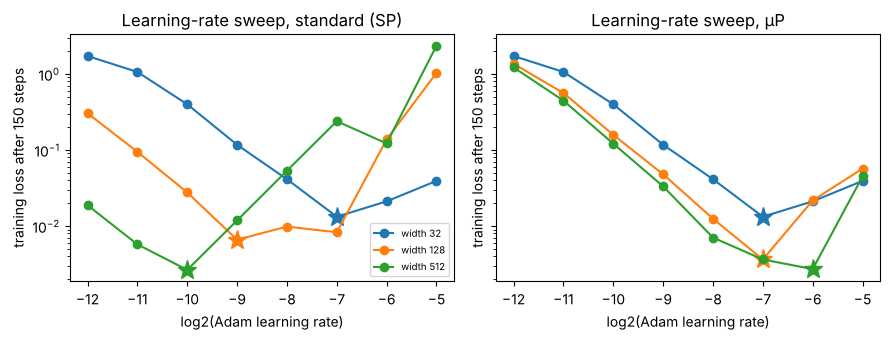

In [5]:
def final_loss(width, param, lr, steps=150, bs=64, seed=0):
    params, mult = make_mlp(width, param, seed)
    opt = make_adam(params, mult, lr)
    g = torch.Generator().manual_seed(seed)
    for step in range(steps):
        idx = torch.randint(len(Xtr), (bs,), generator=g)
        loss = F.cross_entropy(forward(params, Xtr[idx]), ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        full = F.cross_entropy(forward(params, Xtr), ytr).item()
    return full if math.isfinite(full) else float("nan")


log2_lrs = list(range(-12, -4))
sweep_widths = [32, 128, 512]
sweep = {}
t0 = time.time()
for param in ["SP", "muP"]:
    for width in sweep_widths:
        if param == "muP" and width == BASE:
            sweep[(param, width)] = sweep[("SP", width)]          # identical networks at the base width
            continue
        sweep[(param, width)] = [final_loss(width, param, 2.0 ** k) for k in log2_lrs]
print("training loss after 150 steps; columns are log2(learning rate) =", log2_lrs)
for (param, width), losses in sweep.items():
    best = log2_lrs[int(np.nanargmin(losses))]
    print(f"{param:3s} width {width:5d}: best log2 lr {best:4d} | " + " ".join(f"{v:.3f}" for v in losses))
print(f"(sweep took {time.time() - t0:.0f} s)")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for k, param in enumerate(["SP", "muP"]):
    for width in sweep_widths:
        losses = np.array(sweep[(param, width)])
        line, = ax[k].plot(log2_lrs, losses, "o-", label=f"width {width}")
        j = int(np.nanargmin(losses))
        ax[k].plot(log2_lrs[j], losses[j], "*", ms=14, color=line.get_color())
    ax[k].set(yscale="log", title=f"Learning-rate sweep, {'standard (SP)' if param == 'SP' else 'µP'}",
              xlabel="log2(Adam learning rate)", ylabel="training loss after 150 steps")
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 6. µP for a real model (NOT RUN here)
For transformers, use a library rather than hand-written multipliers. Microsoft's `mup` package implements the rules above (plus attention scaled by 1/d instead of 1/√d). The cell below follows the package README; check it against the current README before you run it.

In [ ]:
# NOT RUN: needs `pip install mup` (Microsoft's µP package); for a real transformer, also a GPU.
import torch.nn as nn
from mup import MuReadout, set_base_shapes, MuAdam

class MLP(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(64, width), nn.ReLU(), nn.Linear(width, width), nn.ReLU())
        self.readout = MuReadout(width, 10)          # the output layer, which µP treats differently
    def forward(self, x):
        return self.readout(self.body(x))

base, delta = MLP(width=32), MLP(width=64)           # two small models tell mup which dimensions are "width"
model = MLP(width=4096)
set_base_shapes(model, base, delta=delta)            # call this before creating the optimizer
opt = MuAdam(model.parameters(), lr=2 ** -7)         # a learning rate tuned at the base width
# The README also describes mup.coord_check (get_coord_data, plot_coord_data) for the coordinate check of section 4.

### TODO
1. Rerun section 3 with Adam (learning rate 1e-3) instead of SGD. Which networks train now, and which still fail? Explain the difference using section 2.
2. Complete the post-normalization block below (normalize **after** the addition, as in the original transformer), add it to section 3 and compare it with pre-normalization at depth 32.
3. In section 5, give µP's output layer a zero initialization (a common µP choice) and check whether the best learning rate still stays put.

In [6]:
# TODO: a post-LN residual block, h = LN(h + W relu(h)). Replace the line marked "replace".
def post_ln_block(h, lin, norm):
    return None                                   # replace with: norm(h + lin(F.relu(h)))

out = post_ln_block(torch.zeros(2, 8), nn.Linear(8, 8), nn.LayerNorm(8))
print("not done yet" if out is None else f"post-LN block works, output shape {tuple(out.shape)}")

not done yet


### What to notice
- **Depth at initialization (section 2).** With PyTorch's default initialization, the gradient that reached layer 1 was 1.4e-23, against 1.4e-4 at layer 50: a factor of about 0.41 per layer. The differences between examples shrank from 0.19 to 2.3e-9, which is only the float32 rounding level (in float64 the true value at layer 50 is about 2e-17). He initialization kept the gradient level (8.6e-5 at layer 1, 1.4e-4 at layer 50). The residual network without normalization exploded instead: an activation spread of 4.1e6 at layer 50 and a gradient of 3.8e3 at layer 1. Pre-LayerNorm kept the growth slow (0.98 to 3.9).
- **Training (section 3).** The default-initialized network never learned (test accuracy 0.10). The plain He-initialized network learned only at the small learning rate (0.771 at 0.003) and failed at 0.03 (0.096). The unnormalized residual network diverged at both rates. With LayerNorm, RMSNorm or ReZero, the residual networks reached 0.927 to 0.947 at 0.003 and 0.960 to 0.969 at 0.03. So these fixes do two things: they make the deep network trainable, and they let it use a 10 times larger learning rate.
- **LayerNorm versus RMSNorm.** They gave nearly the same result (0.962 and 0.969 at 0.03). This is one seed, so treat the difference as noise until you repeat it.
- **Width (section 4).** Under the standard parameterization the logits after five Adam steps grew from 0.62 at width 32 to 24.6 at width 2,048. Under µP they stayed between 0.62 and 0.81.
- **Learning-rate transfer (section 5).** Under SP the best log2 learning rate moved from -7 to -9 to -10 as the width went from 32 to 128 to 512. Under µP it was -7, -7 and -6, within one grid step (at width 512 the losses at -7 and -6 were 0.004 and 0.003, effectively a tie). Under µP the wider network was better at every learning rate; under SP, at log2 learning rate -7, the widest network was the worst (0.239 against 0.013).
- **Limits.** One seed, 150 to 300 steps, small MLPs on 8x8 digits. The papers show these effects in ResNets and in transformers with billions of parameters; here we only see the same mechanisms at toy scale.